In [1]:
from pathlib import Path

import pandas as pd

csv_path = Path("titanic (1) (2).csv")

if not csv_path.exists():
    csv_path = Path("Week3") / "titanic (1) (2).csv"

df = pd.read_csv(csv_path)

print(f"Dataset size: {df.shape[0]} rows and {df.shape[1]} columns")
display(df.head())

print("Missing values:")
print(df.isna().sum())

Dataset size: 891 rows and 8 columns


,PassengerId,Pclass,Name,Sex,Age,Ticket,Fare,Survived
0,1,3,"Braund, Mr. Owen Harris",male,22.0,A/5 21171,7.2500,0
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,PC 17599,71.2833,1
2,3,3,"Heikkinen, Miss. Laina",female,26.0,STON/O2. 3101282,7.9250,1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,113803,53.1000,1
4,5,3,"Allen, Mr. William Henry",male,35.0,373450,8.0500,0


Missing values:
PassengerId      0
Pclass           0
Name             0
Sex              0
Age            177
Ticket           0
Fare             0
Survived         0
dtype: int64


In [2]:
from sklearn.model_selection import train_test_split

features = ["Pclass", "Sex", "Age", "Fare"]

X = df[features].copy()
X["Sex"] = X["Sex"].map({"male": 0, "female": 1})
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1,
    stratify=y,
)

print(f"Training passengers: {len(X_train)}")
print(f"Test passengers: {len(X_test)}")

Training passengers: 623
Test passengers: 268


In [3]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

classifiers = {
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),
    "Logistic regression": LogisticRegression(max_iter=1000),
}

accuracies = {}
confusion_matrices = {}

for name, classifier in classifiers.items():
    # Learn the mean for missing ages and the scaling from the training data
    pipeline = make_pipeline(
        SimpleImputer(strategy="mean"),
        StandardScaler(),
        classifier,
    )

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    accuracies[name] = accuracy_score(y_test, predictions)
    confusion_matrices[name] = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

comparison = (
    pd.Series(accuracies, name="Test accuracy")
    .sort_values(ascending=False)
    .to_frame()
)

display(comparison.style.format({"Test accuracy": "{:.2%}"}))

gap = abs(accuracies["KNN (k=3)"] - accuracies["Logistic regression"]) * 100
print(f"Difference in test accuracy: {gap:.2f} percentage points")

,Test accuracy
KNN (k=3),80.60%
Logistic regression,77.24%


Difference in test accuracy: 3.36 percentage points


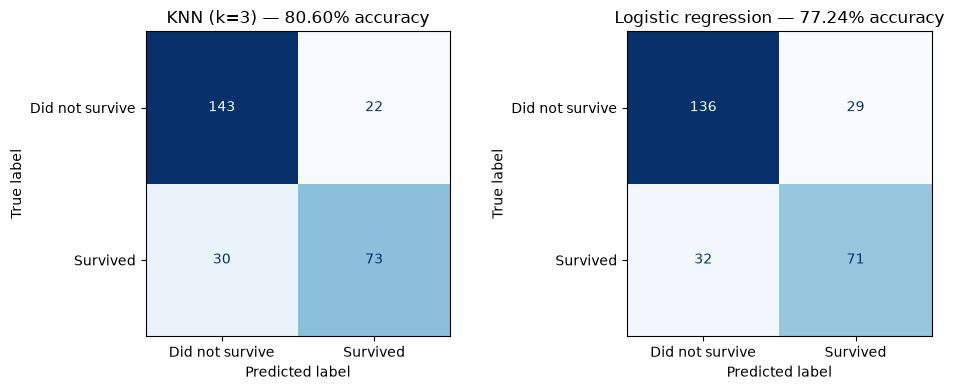

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (name, matrix) in zip(axes, confusion_matrices.items()):
    chart = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Did not survive", "Survived"],
    )
    chart.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} — {accuracies[name]:.2%} accuracy")

plt.tight_layout()
plt.show()